In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob
from scipy.stats import linregress

In [37]:
graph_type = 'RR'
coup_type = 'ising'
d = 4
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=4)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/(d-1)))
    beta_uni = np.arctanh(1/(d-1))
    beta_dob = np.arctanh(1/d)
    print(f"beta_dob = {beta_dob:.6f}, beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")


beta_dob = 0.255413, beta_uni = 0.346574, beta_SG = 0.658479


In [38]:
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/tmp/coal_time_{graph_type}_{coup_type}_d{d}_beta*.csv')]
df = pd.concat(dfs, ignore_index=True)
print("betas:", df['beta'].unique(), "\nsizes:", df['N'].unique())
df

betas: [0.25 0.3  0.33] 
sizes: [   100    300   1000   3000  10000  30000 100000]


,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.25,F_beta_Glauber,False,full_star,50,1000000000,100,50,2068.26,6.479914e+02
1,0.25,F_beta_Glauber,False,full_star,50,1000000000,300,50,7841.92,2.183142e+03
2,0.25,F_beta_Glauber,False,full_star,50,1000000000,1000,50,34242.14,7.369658e+03
3,0.25,F_beta_Glauber,False,full_star,50,1000000000,3000,50,123692.84,1.974548e+04
4,0.25,F_beta_Glauber,False,full_star,50,1000000000,10000,50,474515.88,8.341048e+04
5,0.25,F_beta_Glauber,False,full_star,50,1000000000,30000,50,1656108.66,2.695503e+05
6,0.25,F_beta_Glauber,False,full_star,50,1000000000,100000,50,6199913.08,6.054628e+05
7,0.30,F_beta_Glauber,False,full_star,50,1000000000,100,50,4160.78,2.048281e+03
8,0.30,F_beta_Glauber,False,full_star,50,1000000000,300,50,16437.72,5.329213e+03
9,0.30,F_beta_Glauber,False,full_star,50,1000000000,1000,50,69519.04,1.820552e+04


# Proba of coalescence

In [39]:
max_iter_plot = 10**9
N_plot = [10**2,10**3,10**4,10**5]
if graph_type == 'ER' and coup_type == 'gauss':
    beta_plot = [0.31,0.32,0.33,0.34,0.35,0.36] # beta selection for plotting
    mask = (
        (df['N'].isin(N_plot)) &
        (df['beta'].isin(beta_plot)) &
        (df['max_iter'] == max_iter_plot) 
    )
else:
    mask = (
        (df['N'].isin(N_plot)) &
        (df['max_iter'] == max_iter_plot) 
    )
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.25,F_beta_Glauber,False,full_star,50,1000000000,100,50,2068.26,6.479914e+02
2,0.25,F_beta_Glauber,False,full_star,50,1000000000,1000,50,34242.14,7.369658e+03
4,0.25,F_beta_Glauber,False,full_star,50,1000000000,10000,50,474515.88,8.341048e+04
6,0.25,F_beta_Glauber,False,full_star,50,1000000000,100000,50,6199913.08,6.054628e+05
7,0.30,F_beta_Glauber,False,full_star,50,1000000000,100,50,4160.78,2.048281e+03
9,0.30,F_beta_Glauber,False,full_star,50,1000000000,1000,50,69519.04,1.820552e+04
11,0.30,F_beta_Glauber,False,full_star,50,1000000000,10000,50,1008877.78,1.451197e+05
13,0.30,F_beta_Glauber,False,full_star,50,1000000000,100000,50,13151175.02,1.506141e+06
14,0.33,F_beta_Glauber,False,full_star,50,1000000000,100,50,7118.16,3.835489e+03
16,0.33,F_beta_Glauber,False,full_star,50,1000000000,1000,50,155881.58,5.041064e+04


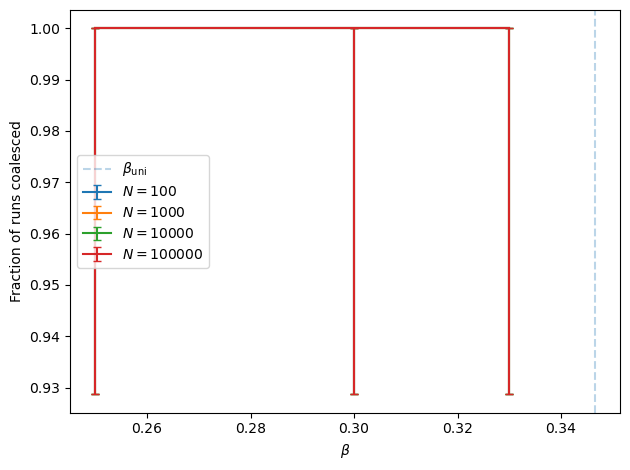

In [40]:
fig, ax = plt.subplots()

for N in df_filtered['N'].unique():
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    ax.errorbar(sub_df['beta'], p,
                yerr=[err_down, err_up],
                label=rf'$N={N}$', capsize=3)

ax.axvline(beta_uni, linestyle='--', alpha=0.3, label=rf'$\beta_\mathrm{{uni}}$')
ax.set_xlabel(rf'$\beta$')
ax.set_ylabel('Fraction of runs coalesced')
ax.legend()
plt.tight_layout()
plt.show()

In [26]:
fig.savefig(f'../results/perm/coal_frac_{graph_type}_{coup_type}_d{d}.png', dpi=600, bbox_inches='tight')

# Scaling of coalescence times

In [41]:
max_iter_plot = 10**9
if graph_type == 'ER' and coup_type == 'gauss':
    beta_plot = [0.3,0.31,0.2,0.27,0.28,0.29,0.32] # beta selection for plotting
elif graph_type == 'ER' and coup_type == 'ising':
    beta_plot = [0.23,0.24,0.25] # beta selection for plotting
else:
    beta_plot = df['beta'].unique()

mask = (
    (df['n_coal'] == df['n_runs']) & # plot only beta values for which every run has coalesced (for unbiased averages)
    (df['beta'].isin(beta_plot)) &
    (df['max_iter'] == max_iter_plot) 
)
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.25,F_beta_Glauber,False,full_star,50,1000000000,100,50,2068.26,6.479914e+02
1,0.25,F_beta_Glauber,False,full_star,50,1000000000,300,50,7841.92,2.183142e+03
2,0.25,F_beta_Glauber,False,full_star,50,1000000000,1000,50,34242.14,7.369658e+03
3,0.25,F_beta_Glauber,False,full_star,50,1000000000,3000,50,123692.84,1.974548e+04
4,0.25,F_beta_Glauber,False,full_star,50,1000000000,10000,50,474515.88,8.341048e+04
5,0.25,F_beta_Glauber,False,full_star,50,1000000000,30000,50,1656108.66,2.695503e+05
6,0.25,F_beta_Glauber,False,full_star,50,1000000000,100000,50,6199913.08,6.054628e+05
7,0.30,F_beta_Glauber,False,full_star,50,1000000000,100,50,4160.78,2.048281e+03
8,0.30,F_beta_Glauber,False,full_star,50,1000000000,300,50,16437.72,5.329213e+03
9,0.30,F_beta_Glauber,False,full_star,50,1000000000,1000,50,69519.04,1.820552e+04


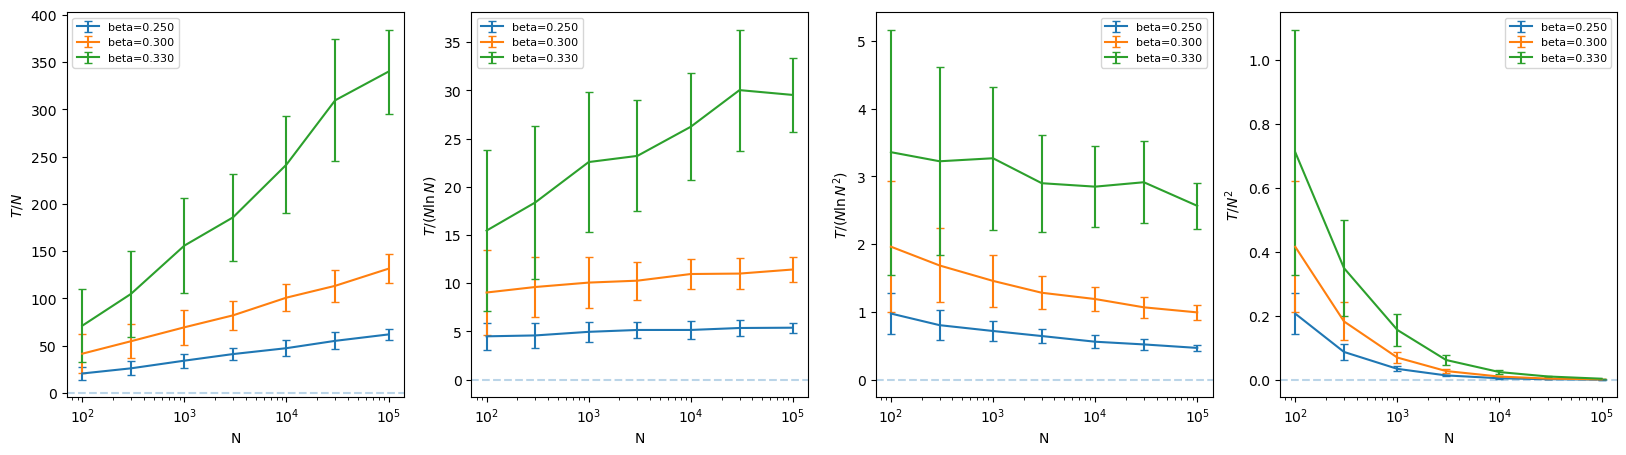

In [42]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / (N \ln N^2)$': (lambda N, T: T / (N * np.log(N)**2), 
                          lambda N, T, sT: sT / (N * np.log(N)**2)),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}
for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in sorted(df_filtered['beta'].unique()):
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT), label=f'beta={beta:.3f}', capsize=3)
    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.set_xscale('log')   
    ax.legend(fontsize=8)
plt.show()

beta=0.250 [NlnN]: A1=6.0233 ± 0.1058, B1=-7.4278 ± 0.7397, R²=0.9528
beta=0.250 [N**D]:  C=10.7466 ± 0.9683, D=1.1586 ± 0.0108, R²=0.9996
beta=0.250 [N(lnN)²]: A2=0.1501 ± 0.0174, B2=3.8085 ± 0.1218, R²=0.9949

beta=0.300 [NlnN]: A1=12.7655 ± 0.2316, B1=-17.8243 ± 1.6196, R²=0.9604
beta=0.300 [N**D]:  C=21.2560 ± 1.7551, D=1.1637 ± 0.0099, R²=0.9996
beta=0.300 [N(lnN)²]: A2=0.3553 ± 0.0242, B2=7.4862 ± 0.1690, R²=0.9975

beta=0.330 [NlnN]: A1=39.1811 ± 1.6606, B1=-114.0587 ± 11.6106, R²=0.9507
beta=0.330 [N**D]:  C=28.7946 ± 4.3159, D=1.2261 ± 0.0179, R²=0.9989
beta=0.330 [N(lnN)²]: A2=2.2758 ± 0.1776, B2=5.3830 ± 1.2419, R²=0.7898



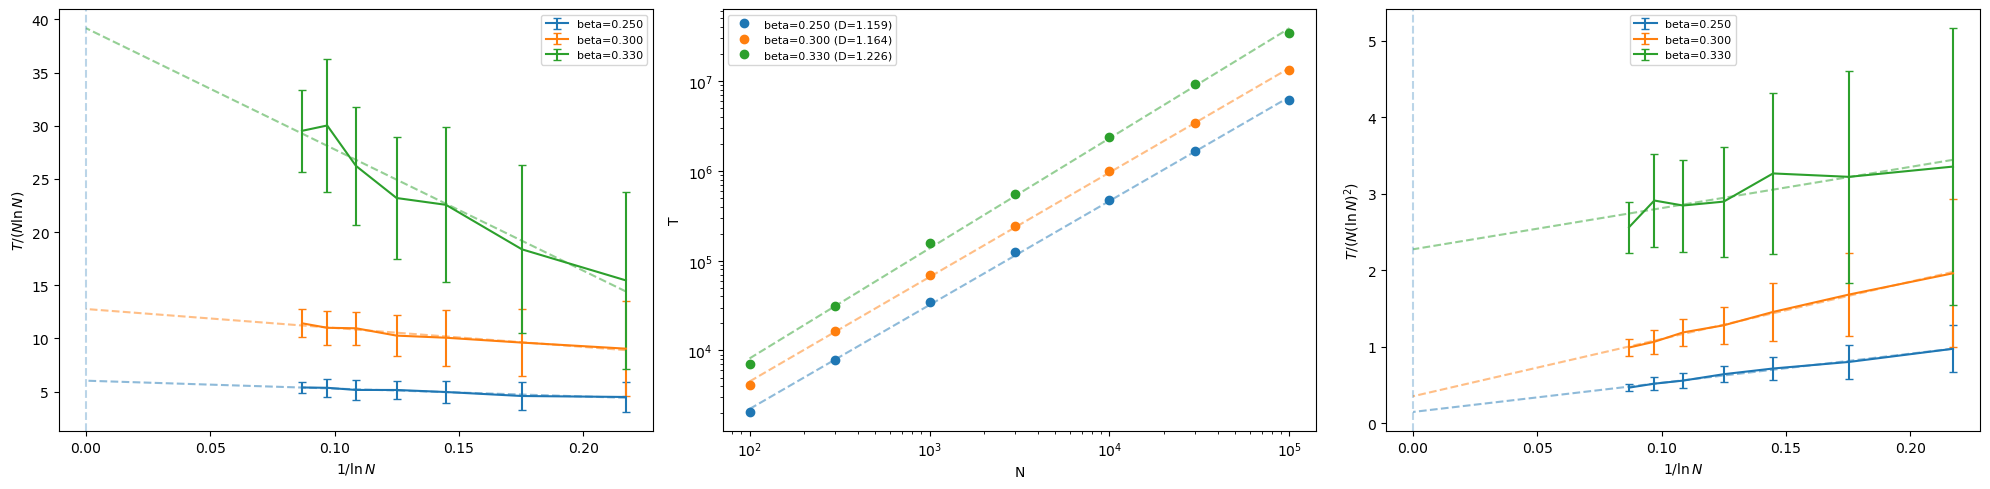

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fit_coeffs = {}

for beta in sorted(df_filtered['beta'].unique()):
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values
    sT = sub_df['std_coal_time'].values

    # --- plot 1: T/(NlnN) vs 1/lnN ---
    x = 1 / np.log(N)
    y = T / (N * np.log(N))
    yerr = sT / (N * np.log(N))
    eb = axes[0].errorbar(x, y, yerr=yerr, label=f'beta={beta:.3f}', capsize=3)
    color = eb.lines[0].get_color() # reuse same color for fit line
    res1 = linregress(x, y)  # slope=B1, intercept=A1
    x_fit = np.linspace(x.max(), 0, 100)
    axes[0].plot(x_fit, res1.slope * x_fit + res1.intercept, linestyle='--', alpha=0.5, color=color)
    print(f"beta={beta:.3f} [NlnN]: A1={res1.intercept:.4f} ± {res1.intercept_stderr:.4f}, "
          f"B1={res1.slope:.4f} ± {res1.stderr:.4f}, R²={res1.rvalue**2:.4f}")

    # --- plot 2: log T vs log N ---
    res2 = linregress(np.log(N), np.log(T))
    D = res2.slope
    C = np.exp(res2.intercept)
    C_err = C * res2.intercept_stderr
    axes[1].loglog(N, T, 'o', color=color, label=f'beta={beta:.3f} (D={D:.3f})')
    axes[1].loglog(N, C * N**D, '--', alpha=0.5, color=color)
    print(f"beta={beta:.3f} [N**D]:  C={C:.4f} ± {C_err:.4f}, "
          f"D={D:.4f} ± {res2.stderr:.4f}, R²={res2.rvalue**2:.4f}")

    # --- plot 3: T/(N(lnN)^2) vs 1/lnN ---
    y3 = T / (N * np.log(N)**2)
    yerr3 = sT / (N * np.log(N)**2)
    axes[2].errorbar(x, y3, yerr=yerr3, capsize=3, color=color, label=f'beta={beta:.3f}')
    res3 = linregress(x, y3)  # intercept=A2, slope=B2
    axes[2].plot(x_fit, res3.slope * x_fit + res3.intercept, linestyle='--', alpha=0.5, color=color)
    print(f"beta={beta:.3f} [N(lnN)²]: A2={res3.intercept:.4f} ± {res3.intercept_stderr:.4f}, "
        f"B2={res3.slope:.4f} ± {res3.stderr:.4f}, R²={res3.rvalue**2:.4f}\n")

    fit_coeffs[beta] = {
        # NlnN fit 
        'A1': res1.intercept, 'A1_err': res1.intercept_stderr,
        'B1': res1.slope,     'B1_err': res1.stderr,
        'r2_NlnN': res1.rvalue**2,
        # power law fit
        'C': C,               'C_err': C_err,
        'D': D,               'D_err': res2.stderr,
        'r2_powerlaw': res2.rvalue**2,
        'A2': res3.intercept, 'A2_err': res3.intercept_stderr,
        'B2': res3.slope,     'B2_err': res3.stderr,
        'r2_NlnN2': res3.rvalue**2,
    }

axes[0].axvline(0, linestyle='--', alpha=0.3)
axes[0].set_xlabel(r'$1 / \ln N$')
axes[0].set_ylabel(r'$T / (N \ln N)$')
axes[0].legend(fontsize=8)

axes[1].set_xlabel('N')
axes[1].set_ylabel('T')
axes[1].legend(fontsize=8)

axes[2].axvline(0, linestyle='--', alpha=0.3)
axes[2].set_xlabel(r'$1 / \ln N$')
axes[2].set_ylabel(r'$T / (N (\ln N)^2)$')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

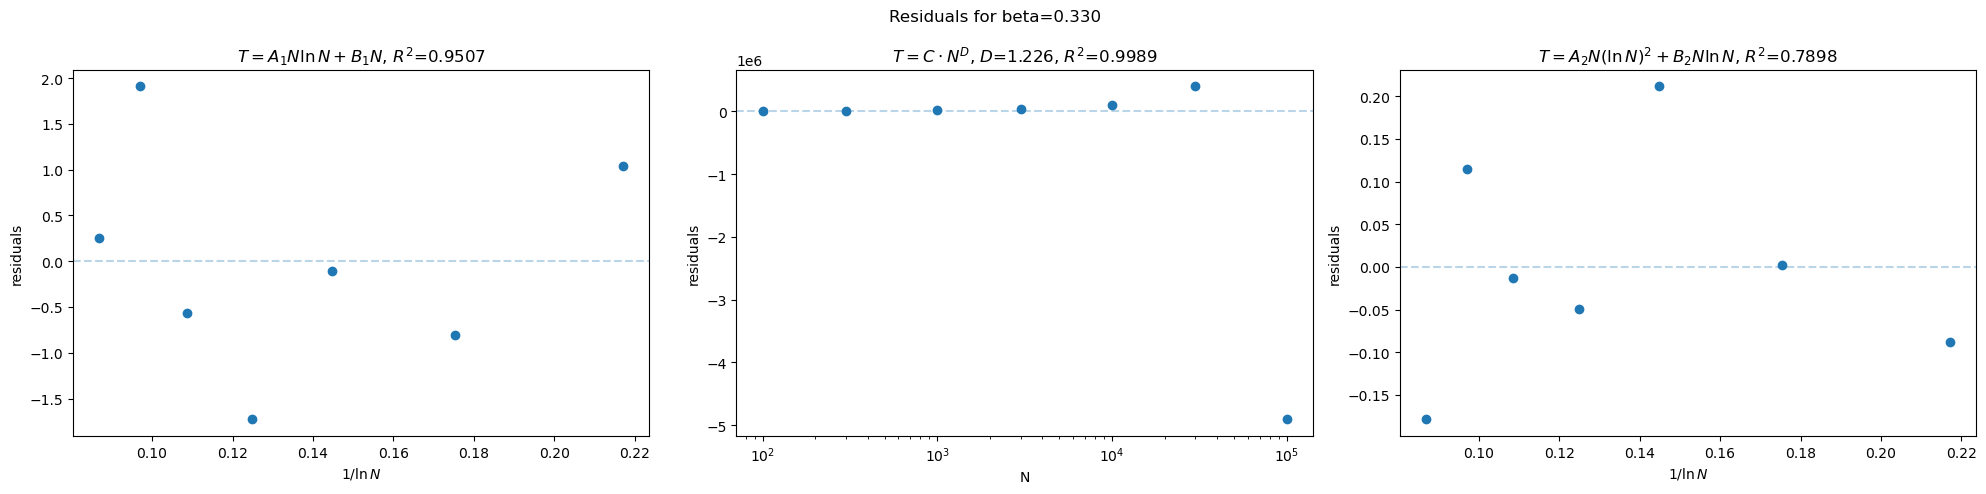

In [52]:
beta_sel = 0.33

sub_df = df_filtered[df_filtered['beta'] == beta_sel].sort_values('N')
N = sub_df['N'].values
T = sub_df['mean_coal_time'].values

x = 1 / np.log(N)
y = T / (N * np.log(N))

fc = fit_coeffs[beta_sel]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# --- residuals of NlnN fit ---
y_pred1 = fc['A1'] + fc['B1'] * x
residuals1 = y - y_pred1
axes[0].axhline(0, linestyle='--', alpha=0.3)
axes[0].plot(x, residuals1, 'o')
axes[0].set_xlabel(r'$1 / \ln N$')
axes[0].set_ylabel('residuals')
axes[0].set_title(rf"$T = A_1 N\ln N + B_1 N$, $R^2$={fc['r2_NlnN']:.4f}")

# --- residuals of power law fit ---
y_pred2 = fc['C'] * N**fc['D']
residuals2 = T - y_pred2
axes[1].axhline(0, linestyle='--', alpha=0.3)
axes[1].plot(N, residuals2, 'o')
axes[1].set_xscale('log')
axes[1].set_xlabel('N')
axes[1].set_ylabel('residuals')
axes[1].set_title(rf"$T = C \cdot N^D$, $D$={fc['D']:.3f}, $R^2$={fc['r2_powerlaw']:.4f}")

# --- residuals of N(lnN)^2 fit ---
y3 = T / (N * np.log(N)**2)
y_pred3 = fc['A2'] + fc['B2'] * x
residuals3 = y3 - y_pred3
axes[2].axhline(0, linestyle='--', alpha=0.3)
axes[2].plot(x, residuals3, 'o')
axes[2].set_xlabel(r'$1 / \ln N$')
axes[2].set_ylabel('residuals')
axes[2].set_title(rf"$T = A_2 N(\ln N)^2 + B_2 N\ln N$, $R^2$={fc['r2_NlnN2']:.4f}")

fig.suptitle(f'Residuals for beta={beta_sel:.3f}', fontsize=12)
plt.tight_layout()
plt.show()

In [53]:
# R² of power law fit in linear space (comparable to NlnN R²)
y_pred_linear = fc['C'] * N**fc['D']
ss_res = np.sum((T - y_pred_linear)**2)
ss_tot = np.sum((T - np.mean(T))**2)
r2_powerlaw_linear = 1 - ss_res / ss_tot
print(f"Power law R² in linear space: {r2_powerlaw_linear:.4f}")

Power law R² in linear space: 0.9742


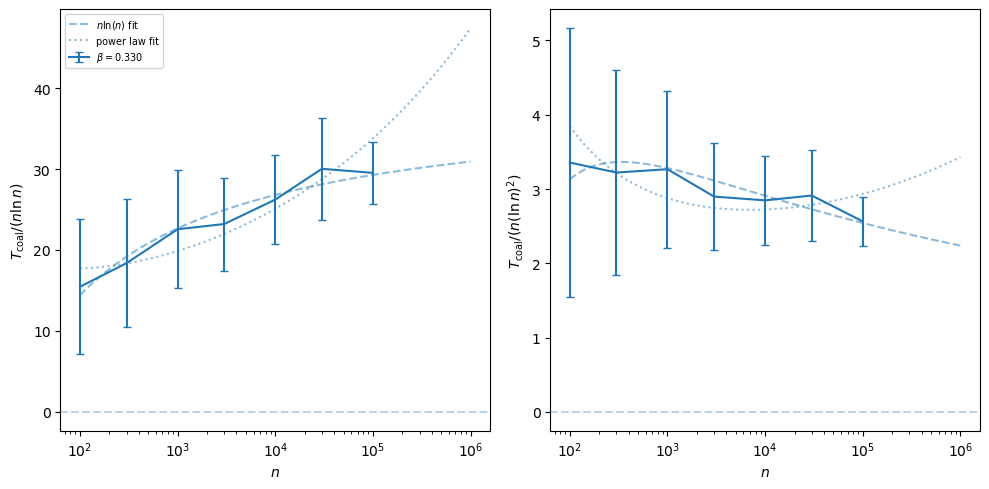

In [54]:
#fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
scalings = {
#    r'$T / N$': (lambda N, T: T / N,
#                 lambda N, T, sT: sT / N),
    rf'$T_\mathrm{{coal}} / (n \ln n)$': (lambda N, T: T / (N * np.log(N)),
                          lambda N, T, sT: sT / (N * np.log(N))),
    rf'$T_\mathrm{{coal}} / (n (\ln n)^2)$': (lambda N, T: T / (N * np.log(N)**2),
                            lambda N, T, sT: sT / (N * np.log(N)**2)),
#    r'$T / N^2$': (lambda N, T: T / N**2,
#                   lambda N, T, sT: sT / N**2),
}

N_fit = np.logspace(np.log10(100), np.log10(1e6), 300)  # smooth curve for fit

for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in [beta_sel]: #sorted(df_filtered['beta'].unique()):
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values

        eb = ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT),
                         label=rf'$\beta={beta:.3f}$', capsize=3)
        color = eb.lines[0].get_color()

        fc = fit_coeffs[beta]

        # NlnN fit: T = A1*N*lnN + B1*N, plot through each scaling
        T_NlnN = fc['A1'] * N_fit * np.log(N_fit) + fc['B1'] * N_fit
        ax.plot(N_fit, scaling_fn(N_fit, T_NlnN), '--', color=color, alpha=0.5, label=rf'$n\ln(n)$ fit')

        # power law fit: T = C * N**D
        T_power = fc['C'] * N_fit**fc['D']
        ax.plot(N_fit, scaling_fn(N_fit, T_power), ':', color=color, alpha=0.5, label=f'power law fit')

        # N(lnN)^2 fit: T = A2*N*(lnN)^2 + B2*N*lnN
        T_NlnN2 = fc['A2'] * N_fit * np.log(N_fit)**2 + fc['B2'] * N_fit * np.log(N_fit)
#        ax.plot(N_fit, scaling_fn(N_fit, T_NlnN2), '-.', color=color, alpha=0.5, label=r'$N(\ln N)^2$ fit')

    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel(rf'$n$')
    ax.set_ylabel(label)
    ax.set_xscale('log')

# single legend on last ax
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [55]:
fig.savefig(f'../results/perm/coal_scaling_{graph_type}_{coup_type}_d{d}_beta{beta_sel:.3f}.png', dpi=500, bbox_inches='tight')

In [ ]:
K=30
Q=-100
delta = 1.21
aa = 3
cc=1
def f(n,K,Q): 
    return K*n*np.log(n)+Q*n
def f2(n,K,Q): 
    return K*n*np.log(n)**2+Q*n*np.log(n)
def g(n,aa, delta, cc): 
    return aa*(n**delta) + cc*n
nr = np.arange(100,10**6,10)
plt.plot(nr,f(nr,K,Q)/(nr*np.log(nr)) )
plt.plot(nr,f2(nr,2,2)/(nr*np.log(nr)) )
plt.plot(nr,g(nr,aa,delta,cc)/(nr*np.log(nr)) )

#plt.plot(nr,f(nr,K,Q)/(nr*(np.log(nr)**2)) )
#plt.plot(nr,f2(nr,2,2)/(nr*(np.log(nr)**2)) )
#plt.plot(nr,g(nr,aa,delta,cc)/(nr*(np.log(nr)**2)) )

#plt.plot(nr,f(nr,K,Q)/(nr**2))
#plt.plot(nr,f2(nr,2,2)/(nr**2))
#plt.plot(nr,g(nr,aa,delta,cc)/(nr**2))

plt.xscale('log')